In [ ]:
# Descomprimir el dataset
!unzip /content/dataset2.zip -d /content/dataset/ > /dev/null

In [ ]:
# instalar la librería que contiene los modelos YOLO
!pip install -q ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 30.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 1.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 96.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 72.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 50.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 12.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 7.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 76.9 MB/s eta 0:00:00


In [ ]:
# para ver que tarjeta grafica nos dio google colab
!nvidia-smi

Sun May  4 02:07:28 2025       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 550.54.15              Driver Version: 550.54.15      CUDA Version: 12.4     |
|-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
# importamos los modulos necesarios
import os
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
# Configuramos los paths
model_pretrained = 'yolo11n.pt'  # Modelo base
data_yaml = '/content/dataset/data2.yaml'  # Para entrenamiento (train + val)
test_yaml = '/content/dataset/test2.yaml'  # Para test final

# Experimento general
project_folder = 'runs'

# nombre del experimento, si queremos experimentar con otro le cambiamos este nombre
experiment_name = 'detect_train'

# Cargamos el modelo
model = YOLO(model_pretrained)

In [ ]:
model.names

{0: 'person',
 1: 'bicycle',
 2: 'car',
 3: 'motorcycle',
 4: 'airplane',
 5: 'bus',
 6: 'train',
 7: 'truck',
 8: 'boat',
 9: 'traffic light',
 10: 'fire hydrant',
 11: 'stop sign',
 12: 'parking meter',
 13: 'bench',
 14: 'bird',
 15: 'cat',
 16: 'dog',
 17: 'horse',
 18: 'sheep',
 19: 'cow',
 20: 'elephant',
 21: 'bear',
 22: 'zebra',
 23: 'giraffe',
 24: 'backpack',
 25: 'umbrella',
 26: 'handbag',
 27: 'tie',
 28: 'suitcase',
 29: 'frisbee',
 30: 'skis',
 31: 'snowboard',
 32: 'sports ball',
 33: 'kite',
 34: 'baseball bat',
 35: 'baseball glove',
 36: 'skateboard',
 37: 'surfboard',
 38: 'tennis racket',
 39: 'bottle',
 40: 'wine glass',
 41: 'cup',
 42: 'fork',
 43: 'knife',
 44: 'spoon',
 45: 'bowl',
 46: 'banana',
 47: 'apple',
 48: 'sandwich',
 49: 'orange',
 50: 'broccoli',
 51: 'carrot',
 52: 'hot dog',
 53: 'pizza',
 54: 'donut',
 55: 'cake',
 56: 'chair',
 57: 'couch',
 58: 'potted plant',
 59: 'bed',
 60: 'dining table',
 61: 'toilet',
 62: 'tv',
 63: 'laptop',
 64: 'mou

In [ ]:
# Entrenamos el modelo, con los parametros seteados anteriormente
results = model.train(
    data=data_yaml,
    epochs=80,
    patience=10,
    imgsz=640,
    batch=16,
    project=project_folder,
    name=experiment_name,
    exist_ok=True,  # Permite sobrescribir la carpeta si ya existe
)

Ultralytics 8.3.126 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data2.yaml, degrees=0.0, deterministic=True, device=cuda:0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=detect_train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=10, perspective=0.0, plots=True, pose=12.0, pret

100%|██████████| 755k/755k [00:00<00:00, 19.6MB/s]

Overriding model.yaml nc=80 with nc=81

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  1     87040  ultralytics.nn.modules.block.C3k2            [128, 128, 1, True]           
  7                  -1  1    295424  ultralytic

YOLO11n summary: 181 layers, 2,625,542 parameters, 2,625,526 gradients, 6.6 GFLOPs

Transferred 448/499 items from pretrained weights
Freezing layer 'model.23.dfl.conv.weight'
AMP: running Automatic Mixed Precision (AMP) checks...
AMP: checks passed ✅
train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 18.1±9.2 MB/s, size: 44.2 KB)


train: Scanning /content/dataset/train/labels... 717 images, 2 backgrounds, 0 corrupt: 100%|██████████| 717/717 [00:00<00:00, 879.40it/s]

...

      45/80      3.62G      0.572     0.6472     0.8235         51        640: 100%|██████████| 45/45 [00:14<00:00,  3.21it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:00<00:00,  3.55it/s]

                   all         69         94      0.965      0.947      0.962      0.865
EarlyStopping: Training stopped early as no improvement observed in last 10 epochs. Best results observed at epoch 35, best model saved as best.pt.
To update EarlyStopping(patience=10) pass a new patience value, i.e. `patience=300` or use `patience=0` to disable EarlyStopping.



45 epochs completed in 0.197 hours.
Optimizer stripped from runs/detect_train/weights/last.pt, 5.5MB
Optimizer stripped from runs/detect_train/weights/best.pt, 5.5MB

Validating runs/detect_train/weights/best.pt...
Ultralytics 8.3.126 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,617,701 parameters, 0 gradients, 6.5 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:01<00:00,  2.33it/s]


                   all         69         94      0.978      0.935      0.965       0.87
                person         69         94      0.978      0.935      0.965       0.87
Speed: 0.3ms preprocess, 3.5ms inference, 0.0ms loss, 3.2ms postprocess per image
Results saved to runs/detect_train


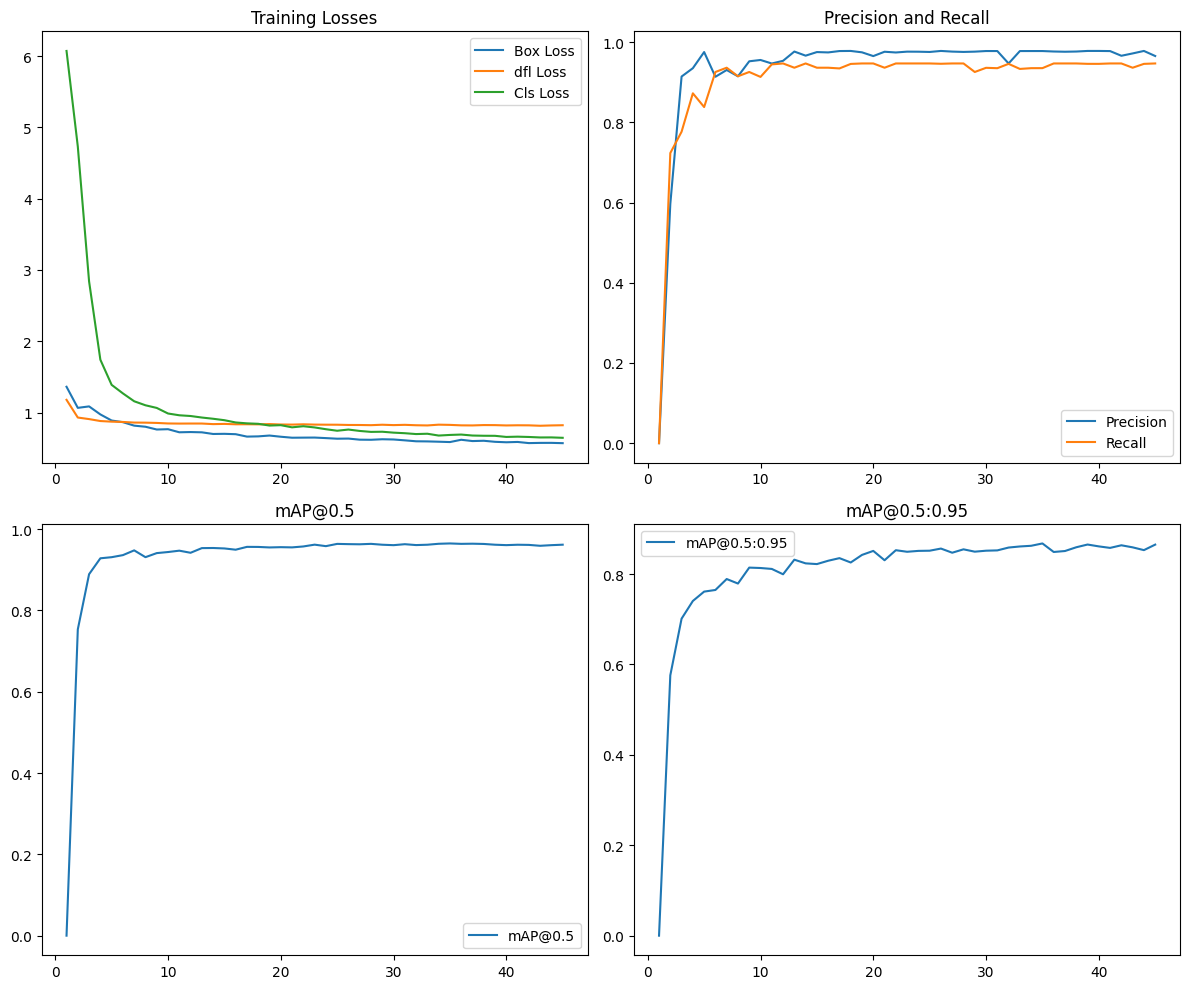

In [ ]:
# Visualización de las métricas obtenidas post-entrenamiento

# Leer el CSV de métricas
results_dir = os.path.join(project_folder, experiment_name)
csv_path = os.path.join(results_dir, 'results.csv')

metrics_df = pd.read_csv(csv_path)


# Graficamos los distintos tipos de loss
fig, axs = plt.subplots(2, 2, figsize=(12, 10))

# Losses
axs[0, 0].plot(metrics_df['epoch'], metrics_df['train/box_loss'], label='Box Loss')
axs[0, 0].plot(metrics_df['epoch'], metrics_df['train/dfl_loss'], label='dfl Loss')
axs[0, 0].plot(metrics_df['epoch'], metrics_df['train/cls_loss'], label='Cls Loss')
axs[0, 0].set_title('Training Losses')
axs[0, 0].legend()

# Precision and Recall
axs[0, 1].plot(metrics_df['epoch'], metrics_df['metrics/precision(B)'], label='Precision')
axs[0, 1].plot(metrics_df['epoch'], metrics_df['metrics/recall(B)'], label='Recall')
axs[0, 1].set_title('Precision and Recall')
axs[0, 1].legend()

# mAP@0.5
axs[1, 0].plot(metrics_df['epoch'], metrics_df['metrics/mAP50(B)'], label='mAP@0.5')
axs[1, 0].set_title('mAP@0.5')
axs[1, 0].legend()

# mAP@0.5:0.95
axs[1, 1].plot(metrics_df['epoch'], metrics_df['metrics/mAP50-95(B)'], label='mAP@0.5:0.95')
axs[1, 1].set_title('mAP@0.5:0.95')
axs[1, 1].legend()

plt.tight_layout()
plt.show()



In [ ]:
# Veremos el rendimiento en el conjunto de test

# Cargamos los pesos del modelo después del entrenamiento
best_model_path = os.path.join(results_dir, 'weights', 'best.pt')
best_model = YOLO(best_model_path)

# Evaluamos el modelo pasandole los datos de test
metrics_test = best_model.val(data=data_yaml, split='test')


Ultralytics 8.3.126 🚀 Python-3.11.12 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLO11n summary (fused): 100 layers, 2,617,701 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 14.6±2.7 MB/s, size: 21.6 KB)


val: Scanning /content/dataset/test/labels... 33 images, 0 backgrounds, 0 corrupt: 100%|██████████| 33/33 [00:00<00:00, 950.38it/s]

val: New cache created: /content/dataset/test/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 3/3 [00:01<00:00,  2.15it/s]


                   all         33         52      0.941      0.922      0.956      0.815
                person         33         52      0.941      0.922      0.956      0.815
Speed: 0.2ms preprocess, 24.5ms inference, 0.0ms loss, 1.5ms postprocess per image
Results saved to runs/detect/val


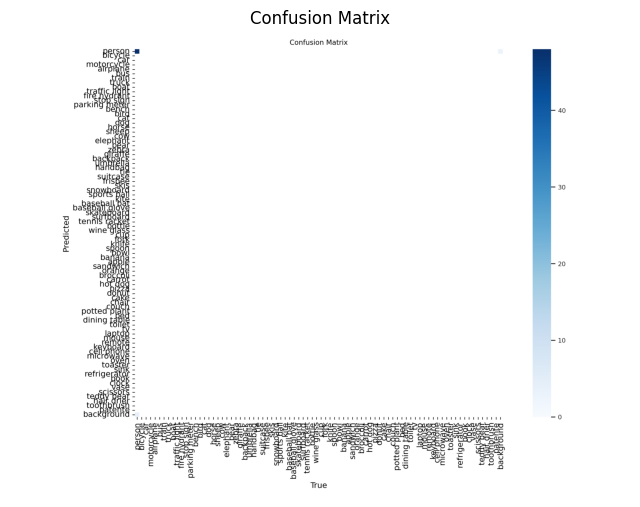

In [ ]:
# Ahora obtenemos la matriz de confusión que se crea al probar el conjunto de test
# el cual se guarda en la carpeta 'detect'

detections = os.path.join(project_folder, 'detect')
conf_matrix_path = os.path.join(detections, 'val', 'confusion_matrix.png')

if os.path.exists(conf_matrix_path):
    img = plt.imread(conf_matrix_path)
    plt.figure(figsize=(8, 8))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Confusion Matrix')
    plt.show()
else:
    print("No se encontró la matriz de confusión.")


In [ ]:
# Utilizamos el mismo modelo para predecir imágenes que no haya visto el modelo para probarlo

predict_results = best_model.predict(
    source='/content/autousa.jpg',  # carpeta o imagen individual
    save=True,                     # guarda resultados en una carpeta
    save_txt=True,                 # guarda las cajas en formato YOLO
    save_conf=True,                # guarda las confianzas (certeza que tiene el modelo del objeto detectado)
)

print("Predicciones terminadas. Resultados guardados en:", predict_results[0].save_dir)



image 1/1 /content/autousa.jpg: 640x640 (no detections), 12.7ms
Speed: 3.6ms preprocess, 12.7ms inference, 0.8ms postprocess per image at shape (1, 3, 640, 640)
Results saved to runs/detect/predict
1 label saved to runs/detect/predict/labels
Predicciones terminadas. Resultados guardados en: runs/detect/predict


In [ ]:
print(model.names)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [ ]:
modelo2 = YOLO('yolo11n.pt')

In [ ]:
modelo2.names

{0: 'person',
 1: 'bicycle',
 2: 'car',
 3: 'motorcycle',
 4: 'airplane',
 5: 'bus',
 6: 'train',
 7: 'truck',
 8: 'boat',
 9: 'traffic light',
 10: 'fire hydrant',
 11: 'stop sign',
 12: 'parking meter',
 13: 'bench',
 14: 'bird',
 15: 'cat',
 16: 'dog',
 17: 'horse',
 18: 'sheep',
 19: 'cow',
 20: 'elephant',
 21: 'bear',
 22: 'zebra',
 23: 'giraffe',
 24: 'backpack',
 25: 'umbrella',
 26: 'handbag',
 27: 'tie',
 28: 'suitcase',
 29: 'frisbee',
 30: 'skis',
 31: 'snowboard',
 32: 'sports ball',
 33: 'kite',
 34: 'baseball bat',
 35: 'baseball glove',
 36: 'skateboard',
 37: 'surfboard',
 38: 'tennis racket',
 39: 'bottle',
 40: 'wine glass',
 41: 'cup',
 42: 'fork',
 43: 'knife',
 44: 'spoon',
 45: 'bowl',
 46: 'banana',
 47: 'apple',
 48: 'sandwich',
 49: 'orange',
 50: 'broccoli',
 51: 'carrot',
 52: 'hot dog',
 53: 'pizza',
 54: 'donut',
 55: 'cake',
 56: 'chair',
 57: 'couch',
 58: 'potted plant',
 59: 'bed',
 60: 'dining table',
 61: 'toilet',
 62: 'tv',
 63: 'laptop',
 64: 'mou